<a href="https://colab.research.google.com/github/BaichalMiras/PII_BaichalMiras_2-CS/blob/main/%D0%91%D0%B0%D0%B9%D1%87%D0%B0%D0%BB_%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D0%BA%D0%B03_2_CS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Практическое занятие
«Attention, Transformer, Embeddings и Self-Supervised Learning»

Self-Attention • Positional Encoding • Embeddings • Autoencoder • Contrastive Learning

Цель работы:
самостоятельно вычислить простой механизм attention;
понять роль Query, Key и Value;
увидеть влияние positional encoding;
поработать с embeddings и cosine similarity;
построить простой autoencoder и посмотреть latent space;
понять идею contrastive learning и positive/negative pairs.

# 1. Self-Attention вручную

Рассмотрим предложение: «Кот увидел мышь». Каждому слову соответствует простой embedding.

In [ ]:
import numpy as np

words = ["кот", "увидел", "мышь"]

X = np.array([
    [1.0, 0.0],
    [0.5, 0.5],
    [0.0, 1.0]
])

print("Words:", words)
print("X:")
print(X)
print("Shape:", X.shape)

Words: ['кот', 'увидел', 'мышь']
X:
[[1.  0. ]
 [0.5 0.5]
 [0.  1. ]]
Shape: (3, 2)


Вопрос: Сколько токенов содержит предложение? Какова размерность каждого embedding? Что означает каждая строка X? Предложение содержит 3 токена: кот, увидел, мышь.
Размерность каждого embedding равна 2 (у каждого слова по два числа).
Каждая строка X - это embedding-вектор одного слова: строка 0 = «кот» = [1, 0], строка 1 = «увидел» = [0.5, 0.5], строка 2 = «мышь» = [0, 1]. Форма матрицы (3, 2) означает «3 токена × 2 признака».

# 2. Получаем Q, K и V

In [ ]:
W_Q = np.array([[1.0, 0.0],[0.0, 1.0]])
W_K = np.array([[1.0, 0.0],[0.0, 1.0]])
W_V = np.array([[1.0, 0.5],[0.5, 1.0]])

Q = X @ W_Q
K = X @ W_K
V = X @ W_V

print("Q:\n", Q)
print("K:\n", K)
print("V:\n", V)
print(Q.shape, K.shape, V.shape)

Q:
 [[1.  0. ]
 [0.5 0.5]
 [0.  1. ]]
K:
 [[1.  0. ]
 [0.5 0.5]
 [0.  1. ]]
V:
 [[1.   0.5 ]
 [0.75 0.75]
 [0.5  1.  ]]
(3, 2) (3, 2) (3, 2)


Вопрос: Почему Q, K и V создаются из одного входа, но с помощью разных матриц весов? Один и тот же embedding слова должен играть в attention три разные роли, поэтому его пропускают через три разные (обучаемые) матрицы весов:
Query (Q) - что это слово сейчас ищет в контексте;
Key (K) - чем это слово может быть найдено, своего рода метка для сравнения с запросами;
Value (V) - какую информацию слово передает дальше, если на него обратили внимание.

Если бы Q и K были одинаковыми, матрица сходства всегда была бы симметричной и слово в первую очередь искал» бы только себя. Разные матрицы позволяют модели самой научиться, что искать, по чему находить и что передавать. В нашем примере W_V отличается от единичной матрицы, поэтому значения V отличаются от исходных embeddings.

# 3. Attention Scores

In [ ]:
scores = Q @ K.T
print(scores)

[[1.  0.5 0. ]
 [0.5 0.5 0.5]
 [0.  0.5 1. ]]


Вопрос: Что означает строка scores[0]? Что означает элемент scores[1, 2]? Почему матрица имеет размер 3×3?
scores[0] = [1.0, 0.5, 0.0] - это оценки совпадения запроса слова «кот» с ключами всех слов: «кот» (1.0), «увидел» (0.5), «мышь» (0.0). Чем больше число, тем сильнее «кот» связан с этим словом.
scores[1, 2] = 0.5 - насколько запрос слова «увидел» совпадает с ключом слова «мышь».
Матрица имеет размер 3×3, потому что каждый из 3 токенов (как query) сравнивается с каждым из 3 токенов (как key): получается n × n пар.

# 4. Scaled Dot-Product Attention

Формула: Attention(Q, K, V) = softmax(QKᵀ / √dₖ) V.

In [ ]:
d_k = K.shape[1]
scaled_scores = scores / np.sqrt(d_k)

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return exp_x / exp_x.sum(axis=-1, keepdims=True)

attention_weights = softmax(scaled_scores)
print(attention_weights)
print("Row sums:", attention_weights.sum(axis=1))

[[0.45552749 0.31986617 0.22460634]
 [0.33333333 0.33333333 0.33333333]
 [0.22460634 0.31986617 0.45552749]]
Row sums: [1. 1. 1.]


Вопрос: Почему сумма каждой строки attention weights должна быть приблизительно равна 1? Softmax превращает каждую строку оценок в распределение вероятностей: все числа положительные, а их сумма равна 1. Строка attention weights показывает, как слово делит своё «внимание» (100%) между всеми словами. Благодаря этому итоговый вектор получается как взвешенное среднее векторов V. «Приблизительно» равна 1 лишь из-за конечной точности чисел с плавающей точкой.

Деление на корень d от k нужно, чтобы при большой размерности скалярные произведения не становились слишком большими: иначе softmax «насыщается» (почти one-hot) и градиенты становятся очень малыми.

# 5. Визуализируйте Attention

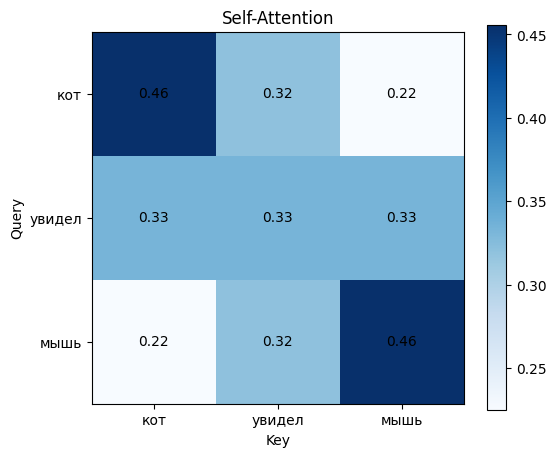

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))
plt.imshow(attention_weights, cmap="Blues")
plt.xticks(range(len(words)), words)
plt.yticks(range(len(words)), words)
plt.xlabel("Key")
plt.ylabel("Query")
plt.title("Self-Attention")

for i in range(len(words)):
    for j in range(len(words)):
        plt.text(j, i, f"{attention_weights[i,j]:.2f}", ha="center", va="center")

plt.colorbar()
plt.show()

Задание: Для каждого слова определите, на какое слово оно обращает больше всего внимания и на какое — меньше всего.
Слово «кот» обращает больше всего внимания на само себя (вес около 0,46), а меньше всего на слово «мышь» (около 0,22). Слово «увидел» распределяет внимание поровну между всеми тремя словами, по 0,33 на каждое, поэтому у него нет ни слова с наибольшим вниманием, ни слова с наименьшим. Слово «мышь» больше всего обращает внимание на само себя (около 0,46), а меньше всего на слово «кот» (около 0,22). Так получается потому, что векторы «кот» и «мышь» перпендикулярны друг другу ([1, 0] и [0, 1]), поэтому они хуже всего совпадают между собой и лучше всего совпадают каждый с самим собой. У слова «увидел» вектор [0,5, 0,5] находится ровно посередине между ними, и его оценки сходства с каждым словом одинаковы (по 0,5), поэтому внимание распределяется равномерно.

# 6. Новый контекстный embedding

In [ ]:
context = attention_weights @ V

print("Исходные embeddings:")
print(X)
print("\nПосле self-attention:")
print(context)

Исходные embeddings:
[[1.  0. ]
 [0.5 0.5]
 [0.  1. ]]

После self-attention:
[[0.80773029 0.69226971]
 [0.75       0.75      ]
 [0.69226971 0.80773029]]


Вопрос: Почему представление слова после self-attention уже зависит не только от самого слова? После self-attention новый вектор слова - это взвешенная сумма векторов V всех слов предложения, где веса берутся из attention matrix. Поэтому, например, представление слова «кот» теперь [0.81, 0.69] вместо [1, 0]: в него «подмешана» информация о «увидел» и «мышь». Так слово получает контекст: его представление зависит от соседей. Это и есть контекстный embedding.

# 7. Эксперимент: измените один токен

In [ ]:
X2 = np.array([
    [1.0, 0.0],
    [0.5, 0.5],
    [1.0, 1.0]
])

Q = X2 @ W_Q
K = X2 @ W_K
V = X2 @ W_V
weights = softmax((Q @ K.T) / np.sqrt(K.shape[1]))
print(weights)

[[0.37007041 0.25985918 0.37007041]
 [0.29204592 0.29204592 0.41590815]
 [0.24825508 0.24825508 0.50348984]]


Задание: Сравните новую attention matrix с исходной. Опишите, как изменение embedding одного токена повлияло на остальные attention weights.

В новой матрице изменился только третий токен: вместо [0, 1] он стал [1, 1], то есть его вектор стал длиннее. При этом поменялись все три строки матрицы, а не только третья. В исходной матрице «кот» распределял внимание как 0,456, 0,320 и 0,225, а теперь как 0,370, 0,260 и 0,370: его внимание к самому себе упало, а к изменённому токену выросло с 0,225 до 0,370, так что он стал смотреть на себя и на третий токен одинаково. Слово «увидел» раньше распределяло внимание поровну (по 0,333), а теперь отдаёт 0,292 первому токену, 0,292 второму и 0,416 третьему, то есть заметно предпочитает изменённый токен. В третьей строке веса были 0,225, 0,320 и 0,456, а стали 0,248, 0,248 и 0,503: третий токен стал смотреть на себя ещё сильнее. Таким образом, во всех строках вес на изменённый токен вырос (0,225 → 0,370, 0,333 → 0,416, 0,456 → 0,503). Это произошло потому, что у него увеличилась длина вектора, а значит, выросли скалярные произведения с запросами всех слов. Поскольку сумма каждой строки после softmax остаётся равной 1, рост одного веса забирает долю у остальных, и большинство других весов уменьшилось. Вывод: токены в self-attention связаны между собой, и изменение embedding одного слова перераспределяет внимание всех остальных слов в предложении.

# 8. Зачем нужен Positional Encoding

Self-attention сам по себе не знает порядок токенов. Сравним «кот увидел мышь» и «мышь увидел кота».

In [ ]:
positions = np.array([
    [0.0, 0.1],
    [0.0, 0.2],
    [0.0, 0.3]
])

X_pos = X + positions
print(X_pos)

[[1.  0.1]
 [0.5 0.7]
 [0.  1.3]]


In [ ]:
# Задание: меняем порядок строк X (мышь, увидел, кот), positional encoding остаётся привязанным к позиции
words_rev = words[::-1]
X_rev = X[::-1]
X_rev_pos = X_rev + positions

def self_attention(Xin):
    Qx, Kx, Vx = Xin @ W_Q, Xin @ W_K, Xin @ W_V
    w = softmax(Qx @ Kx.T / np.sqrt(Kx.shape[1]))
    return w, w @ Vx

print("X_rev + positions:\n", X_rev_pos)

_, out_orig_nopos = self_attention(X)
_, out_rev_nopos  = self_attention(X_rev)
_, out_orig_pos   = self_attention(X_pos)
_, out_rev_pos    = self_attention(X_rev_pos)

print("\n без positional encoding")
for w, v in zip(words, out_orig_nopos):          print("исходный порядок :", f"{w:7s}", v.round(4))
for w, v in zip(words_rev, out_rev_nopos):       print("обратный порядок :", f"{w:7s}", v.round(4))

print("\n с positional encoding")
for w, v in zip(words, out_orig_pos):            print("исходный порядок :", f"{w:7s}", v.round(4))
for w, v in zip(words_rev, out_rev_pos):         print("обратный порядок :", f"{w:7s}", v.round(4))

print("\nбез PE: выход обратного порядка == перевёрнутый выход исходного?",
      np.allclose(out_rev_nopos, out_orig_nopos[::-1]))
print("с PE:   выход обратного порядка == перевёрнутый выход исходного?",
      np.allclose(out_rev_pos, out_orig_pos[::-1]))

X_rev + positions:
 [[0.  1.1]
 [0.5 0.7]
 [1.  0.3]]

 без positional encoding
исходный порядок : кот     [0.8077 0.6923]
исходный порядок : увидел  [0.75 0.75]
исходный порядок : мышь    [0.6923 0.8077]
обратный порядок : мышь    [0.6923 0.8077]
обратный порядок : увидел  [0.75 0.75]
обратный порядок : кот     [0.8077 0.6923]

 с positional encoding
исходный порядок : кот     [0.8908 0.8786]
исходный порядок : увидел  [0.834 0.978]
исходный порядок : мышь    [0.78   1.0726]
обратный порядок : мышь    [0.7888 0.9806]
обратный порядок : увидел  [0.8458 0.9521]
обратный порядок : кот     [0.9031 0.9234]

без PE: выход обратного порядка == перевёрнутый выход исходного? True
с PE:   выход обратного порядка == перевёрнутый выход исходного? False


Задание: Измените порядок строк X, но оставьте positional encoding соответствующим позиции. Сравните результат.
Без positional encoding перестановка строк лишь переставляет строки результата: вектор слова «кот» остаётся ровно тем же [0.81, 0.69] и в предложении «кот увидел мышь», и в «мышь увидел кот». Для модели это один и тот же набор слов (как «мешок слов»), порядок невидим.
С positional encoding к каждому embedding добавляется вектор, зависящий от позиции. Теперь «кот» на 1-й позиции даёт [0.89, 0.88], а на 3-й - [0.90, 0.92]. Контекстные представления слов различаются, значит модель может отличить порядок слов.

Вопрос: Почему Transformer необходимо сообщать информацию о позиции токена?  Self-attention обрабатывает все токены одновременно и вычисляет только попарное сходство, поэтому он инвариантен к перестановке (результат для слов не зависит от того, в каком порядке они расположены). Но порядок несёт смысл: «кот увидел мышь» и «мышь увидела кота» - разные события. Без позиции модель не отличила бы подлежащее от дополнения. Positional encoding возвращает эту информацию.

# 9. Embeddings и пространство признаков

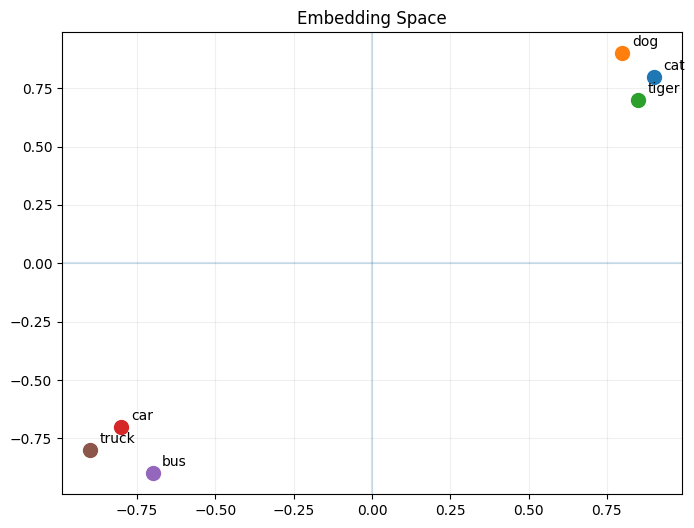

In [ ]:
embeddings = {
    "cat": np.array([0.9, 0.8]),
    "dog": np.array([0.8, 0.9]),
    "tiger": np.array([0.85, 0.7]),
    "car": np.array([-0.8, -0.7]),
    "bus": np.array([-0.7, -0.9]),
    "truck": np.array([-0.9, -0.8])
}

plt.figure(figsize=(8,6))
for word, vector in embeddings.items():
    plt.scatter(vector[0], vector[1], s=100)
    plt.text(vector[0]+0.03, vector[1]+0.03, word)
plt.axhline(0, alpha=0.2)
plt.axvline(0, alpha=0.2)
plt.grid(alpha=0.2)
plt.title("Embedding Space")
plt.show()

Вопрос: Какие объекты расположены близко друг к другу? Почему близость в embedding space полезна? На графике видно две группы: животные (cat, dog, tiger) в правом верхнем углу и транспорт (car, bus, truck) в левом нижнем. Объекты одной смысловой группы расположены близко друг к другу, а группы далеко друг от друга.

Близость в embedding space полезна, потому что расстояние/угол между векторами отражает смысловое сходство. Это позволяет модели: находить похожие объекты (поиск, рекомендации), переносить знания на редкие или новые слова (если модель знает «cat», она может разумно обращаться с «tiger»), а также использовать векторы как удобный числовой вход для других моделей.

# 10. Cosine Similarity

In [ ]:
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

print("cat vs dog:", cosine_similarity(embeddings["cat"], embeddings["dog"]))
print("cat vs car:", cosine_similarity(embeddings["cat"], embeddings["car"]))

cat vs dog: 0.993103448275862
cat vs car: -0.9999694838187877


In [ ]:
#Задание: Посчитайте similarity для пар cat–tiger, car–bus, dog–truck, bus–truck.
pairs = [("cat", "tiger"), ("car", "bus"), ("dog", "truck"), ("bus", "truck")]
for a, b in pairs:
    print(f"{a} - {b}: {cosine_similarity(embeddings[a], embeddings[b]):.4f}")

cat - tiger: 0.9993
car - bus: 0.9818
dog - truck: -0.9931
bus - truck: 0.9833


Задание: Посчитайте similarity для пар cat–tiger, car–bus, dog–truck, bus–truck.

| Пара объектов | Cosine similarity |
|---|---|
| cat - tiger | 0.9993 |
| car - bus | 0.9818 |
| dog - truck | -0.9931 |
| bus - truck | 0.9833 |

Вопрос: Что означает cosine similarity, близкая к 1, 0 и -1? Это косинус угла между векторами, то есть мера совпадения их направления (длина не важна):
около 1 - векторы направлены одинаково, объекты очень похожи по смыслу (cat - tiger, car - bus);
около 0 - векторы перпендикулярны, объекты не связаны между собой;
около -1 - векторы направлены противоположно, объекты «противоположны» в пространстве признаков (dog - truck, cat - car).

# 11. Постройте Autoencoder

In [ ]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()
train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)

class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):   # по умолчанию latent = 2, как в задании
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 28*28),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)
        return reconstructed.view(-1, 1, 28, 28)

100%|██████████| 9.91M/9.91M [00:00<00:00, 60.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.74MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.4MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.97MB/s]


Вопрос: Почему последний слой encoder содержит только 2 значения? Что это заставляет модель делать? Последний слой encoder выдаёт всего 2 числа, то есть вся картинка 28×28 = 784 пикселя сжимается до двух чисел (узкое «горлышко», bottleneck). Это заставляет модель не копировать вход, а выбирать самое важное: форму, наклон, общий вид цифры, отбрасывая мелкие детали. Decoder должен потом восстановить изображение только по этим двум числам. Кроме того, 2 числа - это координаты точки на плоскости, поэтому latent space можно нарисовать

# 12. Обучите Autoencoder

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = Autoencoder().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.MSELoss()

loss_history = []
for epoch in range(5):
    total_loss = 0
    for images, _ in train_loader:
        images = images.to(device)
        optimizer.zero_grad()
        reconstructed = model(images)
        loss = criterion(reconstructed, images)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    loss_history.append(total_loss / len(train_loader))
    print(f"Epoch {epoch+1}: {loss_history[-1]:.4f}")

Device: cpu
Epoch 1: 0.0627
Epoch 2: 0.0518
Epoch 3: 0.0495
Epoch 4: 0.0479
Epoch 5: 0.0467


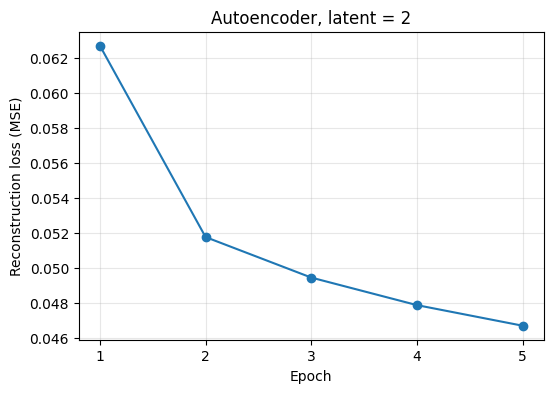

Loss упал с 0.0627 (эпоха 1) до 0.0467 (эпоха 5), то есть на 25.5%


In [ ]:
# Зафиксируем изменение loss по эпохам
plt.figure(figsize=(6,4))
plt.plot(range(1, len(loss_history)+1), loss_history, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Reconstruction loss (MSE)")
plt.title("Autoencoder, latent = 2"); plt.grid(alpha=0.3)
plt.xticks(range(1, len(loss_history)+1))
plt.show()

print(f"Loss упал с {loss_history[0]:.4f} (эпоха 1) до {loss_history[-1]:.4f} (эпоха {len(loss_history)}), "
      f"то есть на {100*(1-loss_history[-1]/loss_history[0]):.1f}%")

Задание: Зафиксируйте, как менялся reconstruction loss по эпохам. Reconstruction loss (MSE) уменьшается от эпохи к эпохе: сильнее всего он падает в первые эпохи, затем снижение замедляется и кривая выходит на плато. Конкретные значения по эпохам выведены в ячейке обучения, а график и итоговое изменение - в ячейке ниже неё. Это значит, что модель постепенно учится всё лучше восстанавливать цифры по двум числам, но при latent = 2 loss не станет близким к нулю: двух чисел недостаточно для хранения всех деталей.

# 13. Original vs Reconstruction

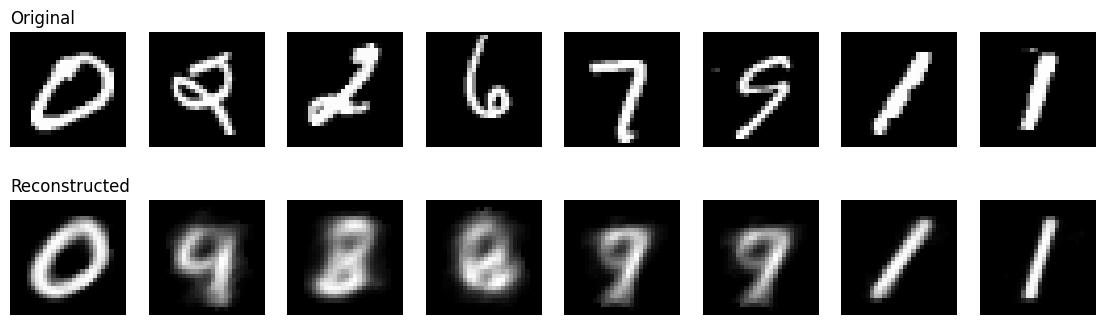

In [ ]:
images, labels = next(iter(train_loader))
images = images[:8].to(device)

with torch.no_grad():
    reconstructed = model(images)

images = images.cpu()
reconstructed = reconstructed.cpu()

fig, axes = plt.subplots(2, 8, figsize=(14,4))
for i in range(8):
    axes[0,i].imshow(images[i].squeeze(), cmap="gray")
    axes[0,i].axis("off")
    axes[1,i].imshow(reconstructed[i].squeeze(), cmap="gray")
    axes[1,i].axis("off")
axes[0,0].set_title("Original", loc="left")
axes[1,0].set_title("Reconstructed", loc="left")
plt.show()

Вопрос: Что модель сохранила хорошо? Какие детали потерялись? Почему reconstruction не является точной копией?
Сохранилось хорошо: общая форма и положение цифры, примерная толщина и наклон, в большинстве случаев - класс цифры (особенно простых, как 0 и 1).
Потерялось: тонкие детали и индивидуальный почерк, чёткие границы штрихов (картинка получается размытой), мелкие особенности формы. У похожих цифр (4/9, 3/5/8, 7/9) модель может восстановить «усреднённую» форму, похожую на другую цифру.
Почему не точная копия: сжатие в 2 числа - это сжатие с потерями: информации о 784 пикселях в двух числах не хватает. Кроме того, MSE штрафует за ошибку в каждом пикселе, и модели выгодно выдавать усреднённое (размытое) изображение, а не рисковать резкими краями. Также обучение было коротким (5 эпох).

# 14. Визуализируйте Latent Space

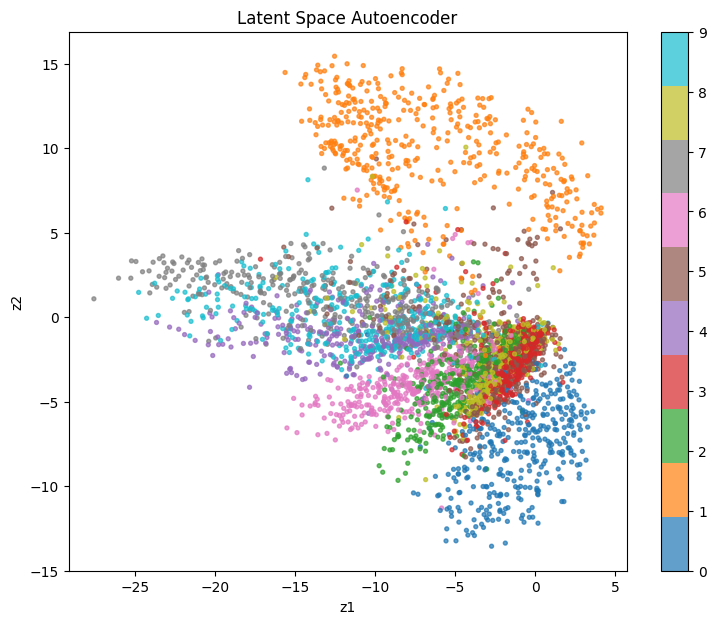

In [ ]:
latents = []
labels_all = []
model.eval()

with torch.no_grad():
    for images, labels in train_loader:
        images = images.to(device)
        z = model.encoder(images)
        latents.append(z.cpu())
        labels_all.append(labels)
        if len(latents) >= 30:
            break

latents = torch.cat(latents).numpy()
labels_all = torch.cat(labels_all).numpy()

plt.figure(figsize=(9,7))
scatter = plt.scatter(latents[:,0], latents[:,1], c=labels_all, cmap="tab10", s=8, alpha=0.7)
plt.colorbar(scatter)
plt.title("Latent Space Autoencoder")
plt.xlabel("z1")
plt.ylabel("z2")
plt.show()

Вопрос: Образуются ли группы цифр? Какие классы находятся рядом? Почему autoencoder не использует labels, но похожие цифры могут оказаться рядом?
Образуются ли группы? Да, частично. Точки одной цифры собираются в области латентной плоскости, однако группы заметно перекрываются, потому что 2 измерения - очень тесное пространство для 10 классов. Лучше всего обычно отделяются простые цифры (0, 1, иногда 6), хуже всего - сложные.
Какие классы рядом? Обычно рядом оказываются визуально похожие цифры: 4 и 9, 3, 5 и 8, 7 и 9 (точное расположение зависит от конкретного запуска, ведь инициализация случайна).
Почему без labels? Autoencoder обучается только восстанавливать картинку и меток никогда не видит. Но чтобы decoder восстановил похожие изображения, их кодам выгодно быть похожими: decoder - плавная функция, и близкие коды дают близкие картинки. Поэтому визуально похожие цифры естественно оказываются рядом, а классы «проявляются» сами собой. Это и есть идея self-supervised learning: структура извлекается из самих данных.

# 15. Эксперимент с размером latent space

Задание: Измените latent size с 2 на 8, затем на 32. Для каждого варианта переобучите модель и сравните reconstruction loss и качество изображений.

  latent= 2  epoch 1: 0.0624
  latent= 2  epoch 2: 0.0517
  latent= 2  epoch 3: 0.0493
  latent= 2  epoch 4: 0.0480
  latent= 2  epoch 5: 0.0471
  latent= 8  epoch 1: 0.0494
  latent= 8  epoch 2: 0.0285
  latent= 8  epoch 3: 0.0259
  latent= 8  epoch 4: 0.0246
  latent= 8  epoch 5: 0.0237
  latent=32  epoch 1: 0.0478
  latent=32  epoch 2: 0.0199
  latent=32  epoch 3: 0.0149
  latent=32  epoch 4: 0.0126
  latent=32  epoch 5: 0.0113


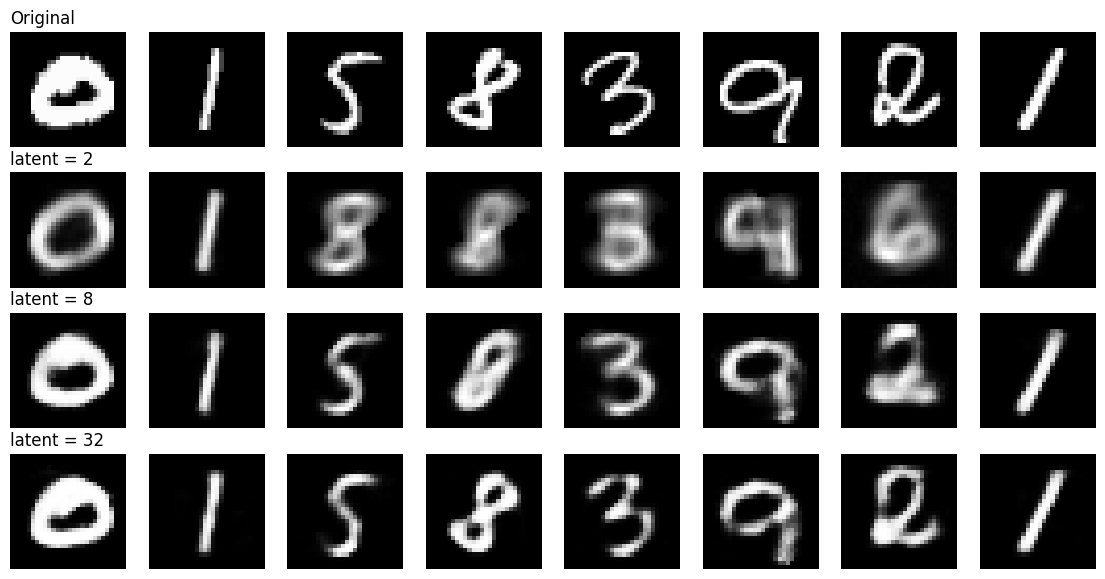

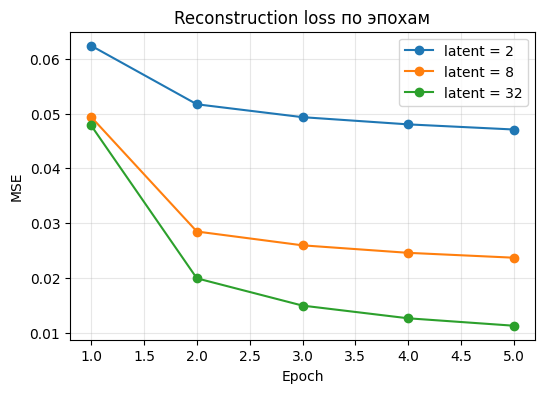

| Latent size | Reconstruction loss (последняя эпоха) | Качество изображения |
|---|---|---|
| 2 | 0.0471 | размытые, форма грубая, похожие цифры путаются |
| 8 | 0.0237 | цифры хорошо узнаваемы, часть мелких деталей потеряна |
| 32 | 0.0113 | очень близки к оригиналу, штрихи чёткие |


In [ ]:
from IPython.display import Markdown, display

def train_autoencoder(latent_dim, epochs=5):
    m = Autoencoder(latent_dim).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=0.001)
    crit = nn.MSELoss()
    hist = []
    for epoch in range(epochs):
        total = 0
        for imgs, _ in train_loader:
            imgs = imgs.to(device)
            opt.zero_grad()
            loss = crit(m(imgs), imgs)
            loss.backward()
            opt.step()
            total += loss.item()
        hist.append(total / len(train_loader))
        print(f"  latent={latent_dim:2d}  epoch {epoch+1}: {hist[-1]:.4f}")
    return m, hist

latent_sizes = [2, 8, 32]
models, histories = {}, {}
for d in latent_sizes:
    models[d], histories[d] = train_autoencoder(d)

# Одни и те же 8 картинок для всех моделей
test_images = next(iter(train_loader))[0][:8].to(device)
fig, axes = plt.subplots(len(latent_sizes)+1, 8, figsize=(14, 7))
for i in range(8):
    axes[0,i].imshow(test_images[i].cpu().squeeze(), cmap="gray"); axes[0,i].axis("off")
for r, d in enumerate(latent_sizes, start=1):
    with torch.no_grad():
        rec = models[d](test_images).cpu()
    for i in range(8):
        axes[r,i].imshow(rec[i].squeeze(), cmap="gray"); axes[r,i].axis("off")
    axes[r,0].set_title(f"latent = {d}", loc="left")
axes[0,0].set_title("Original", loc="left")
plt.show()

# Кривые loss
plt.figure(figsize=(6,4))
for d in latent_sizes:
    plt.plot(range(1, 6), histories[d], marker="o", label=f"latent = {d}")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Reconstruction loss по эпохам")
plt.show()

quality = {2: "размытые, форма грубая, похожие цифры путаются",
           8: "цифры хорошо узнаваемы, часть мелких деталей потеряна",
           32: "очень близки к оригиналу, штрихи чёткие"}
table = "| Latent size | Reconstruction loss (последняя эпоха) | Качество изображения |\n|---|---|---|\n"
for d in latent_sizes:
    table += f"| {d} | {histories[d][-1]:.4f} | {quality[d]} |\n"
display(Markdown(table))

Задание: Измените latent size с 2 на 8, затем на 32. Для каждого варианта переобучите модель и сравните reconstruction loss и качество изображений

| Latent size | Reconstruction loss | Качество изображения |
|---|---|---|
| 2 | самый большой | размытые, форма грубая, похожие цифры путаются |
| 8 | заметно меньше | цифры хорошо узнаваемы, часть мелких деталей потеряна |
| 32 | самый маленький | очень близки к оригиналу, штрихи чёткие |

Вопрос: Что происходит при увеличении размерности latent space? В чём компромисс? С ростом размерности latent space reconstruction loss уменьшается, а изображения становятся чётче: в код помещается больше информации. Цена за это меньшее сжатие. При очень большом latent модель может просто «переписывать» вход почти без сжатия и не учит компактные, осмысленные признаки; пропадает возможность наглядно визуализировать пространство (при 2 можно нарисовать, при 32 нельзя), растут число параметров и затраты. При маленьком latent представление компактное и интерпретируемое, но с большими потерями. Итого компромисс: качество реконструкции против степени сжатия и компактности представления

# 16. Идея Contrastive Learning

В contrastive learning похожие представления стараются расположить ближе, а разные — дальше. Две augmentation одного объекта образуют positive pair; разные объекты могут выступать negative examples.

# Идея:
# cat_original  ---- close ----  crop(cat)
# car           ---- far   ----  cat_original


# 17. Наглядный Contrastive Experiment

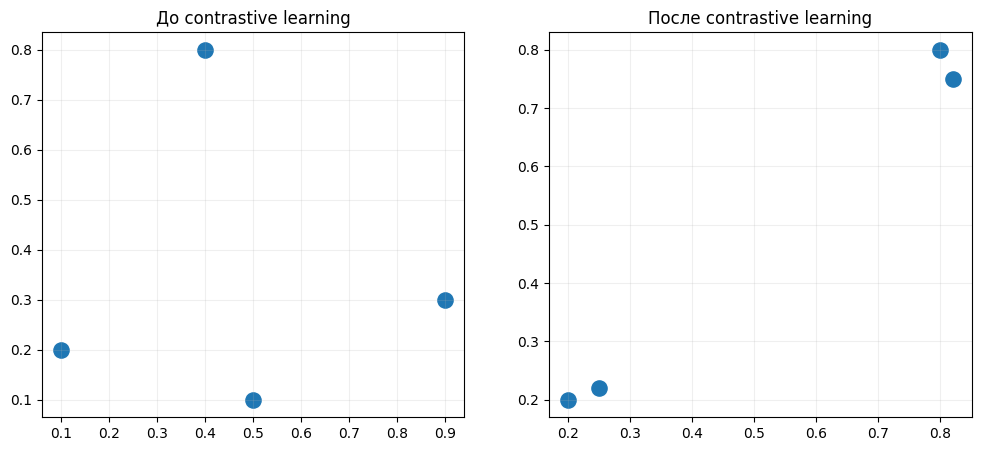

In [ ]:
before = np.array([
    [0.1, 0.2],
    [0.9, 0.3],
    [0.4, 0.8],
    [0.5, 0.1]
])

after = np.array([
    [0.2, 0.2],
    [0.25, 0.22],
    [0.8, 0.8],
    [0.82, 0.75]
])

fig, axes = plt.subplots(1, 2, figsize=(12,5))
axes[0].scatter(before[:,0], before[:,1], s=120)
axes[0].set_title("До contrastive learning")
axes[1].scatter(after[:,0], after[:,1], s=120)
axes[1].set_title("После contrastive learning")
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

Вопрос: Какая основная цель contrastive learning отражена на втором графике? На втором графике отражена основная цель contrastive learning: похожие объекты (positive pairs) стянуты в плотные группы, а непохожие разнесены далеко друг от друга. До обучения 4 точки разбросаны без видимой структуры. После обучения образовалось две компактные группы: две точки около (0.2, 0.2) и две точки около (0.8, 0.8), причём расстояние между группами велико, а внутри группы - мало. Так модель учит представления, в которых близость отражает смысловое сходство, и делает это без меток классов.

# 18. Positive и Negative Pairs

Определите тип каждой пары и объясните решение.

| Пара | Positive / Negative | Почему |
|---|---|---|
| Исходная фотография кота + crop той же фотографии | **Positive** | Это один и тот же объект, обрезка (augmentation) не меняет, что на фото. Представления должны быть близки. |
| Фотография автомобиля + фотография автобуса | **Negative** | Это два разных изображения разных объектов, а не два вида одного. В contrastive learning без меток они считаются разными примерами, и их представления нужно развести. (Они, конечно, оба «транспорт», но positive pair требует именно двух версий одного и того же образца.) |
| Собака + та же фотография с изменённой яркостью | **Positive** | Изменение яркости - допустимая augmentation, смысл (собака) не меняется. |
| Цифра 7 + изображение цифры 2 | **Negative** | Это разные образцы и разные классы, представления должны быть далеки. |

# 19. Самостоятельная часть

Выбран Вариант A - Attention.

Предложение из 5 слов «умный кот быстро поймал мышь».
Embeddings размерности 3 (придуманы вручную). Условно, три признака: «предмет/существо», «действие», «качество/свойство».
Дальше шаг за шагом вычисляем Q, K, V, QKᵀ, scaled scores, softmax и attention output и визуализируем attention matrix.

In [ ]:
np.set_printoptions(precision=3, suppress=True)

words_a = ["умный", "кот", "быстро", "поймал", "мышь"]

# Embeddings (5 токенов, размерность 3): [существо, действие, свойство]
X_a = np.array([
    [0.6, 0.3, 3.0],   # умный  - в основном "свойство"
    [3.0, 0.3, 0.6],   # кот    - в основном "существо"
    [0.3, 0.9, 2.7],   # быстро - "свойство" + немного действия
    [0.6, 3.0, 0.3],   # поймал - в основном "действие"
    [2.7, 0.0, 0.3],   # мышь   - в основном "существо"
])

# Весовые матрицы 3x3 (придуманы вручную)
Wq = np.array([[1.0, 0.5, 0.0],
               [0.0, 1.0, 0.5],
               [0.5, 0.0, 1.0]])
Wk = np.array([[1.0, 0.0, 0.5],
               [0.5, 1.0, 0.0],
               [0.0, 0.5, 1.0]])
Wv = np.array([[0.5, 0.5, 0.0],
               [0.0, 1.0, 0.5],
               [0.5, 0.0, 1.0]])

print("X:\n", X_a, "\nShape:", X_a.shape)

X:
 [[0.6 0.3 3. ]
 [3.  0.3 0.6]
 [0.3 0.9 2.7]
 [0.6 3.  0.3]
 [2.7 0.  0.3]] 
Shape: (5, 3)


In [ ]:
# Шаг 1. Q, K, V
Q_a = X_a @ Wq
K_a = X_a @ Wk
V_a = X_a @ Wv
print("Q:\n", Q_a)
print("K:\n", K_a)
print("V:\n", V_a)

# Проверка вручную для Q[0] = X[0] @ Wq:  0.6*[1,.5,0] + 0.3*[0,1,.5] + 3.0*[.5,0,1]
q0_manual = 0.6*np.array([1,.5,0]) + 0.3*np.array([0,1,.5]) + 3.0*np.array([.5,0,1])
print("\nQ[0] вручную:", q0_manual, "| совпадает:", np.allclose(q0_manual, Q_a[0]))

Q:
 [[2.1  0.6  3.15]
 [3.3  1.8  0.75]
 [1.65 1.05 3.15]
 [0.75 3.3  1.8 ]
 [2.85 1.35 0.3 ]]
K:
 [[0.75 1.8  3.3 ]
 [3.15 0.6  2.1 ]
 [0.75 2.25 2.85]
 [2.1  3.15 0.6 ]
 [2.7  0.15 1.65]]
V:
 [[1.8  0.6  3.15]
 [1.8  1.8  0.75]
 [1.5  1.05 3.15]
 [0.45 3.3  1.8 ]
 [1.5  1.35 0.3 ]]

Q[0] вручную: [2.1  0.6  3.15] | совпадает: True


In [ ]:
# Шаг 2. Attention scores = Q K^T  (матрица 5x5)
scores_a = Q_a @ K_a.T
print("QK^T:\n", scores_a)

# Проверка одного элемента: scores[0,1] = Q[0] . K[1]
print("\nscores[0,1] вручную:", sum(Q_a[0,i]*K_a[1,i] for i in range(3)), "| из матрицы:", scores_a[0,1])

QK^T:
 [[13.05  13.59  11.902  8.19  10.958]
 [ 8.19  13.05   8.662 13.05  10.418]
 [13.523 12.443 12.578  8.662  9.81 ]
 [12.442  8.123 13.117 13.05   5.49 ]
 [ 5.558 10.418  6.03  10.418  8.393]]

scores[0,1] вручную: 13.59 | из матрицы: 13.59


In [ ]:
# Шаг 3. Scaling: делим на sqrt(d_k), d_k = 3
d_k_a = K_a.shape[1]
scaled_a = scores_a / np.sqrt(d_k_a)
print("sqrt(d_k) =", np.sqrt(d_k_a).round(4))
print("Scaled scores:\n", scaled_a)

sqrt(d_k) = 1.7321
Scaled scores:
 [[7.534 7.846 6.872 4.728 6.326]
 [4.728 7.534 5.001 7.534 6.015]
 [7.807 7.184 7.262 5.001 5.664]
 [7.184 4.69  7.573 7.534 3.17 ]
 [3.209 6.015 3.481 6.015 4.845]]


In [ ]:
# Шаг 4. Softmax по строкам
weights_a = softmax(scaled_a)
print("Attention weights:\n", weights_a)
print("Row sums:", weights_a.sum(axis=1))

Attention weights:
 [[0.309 0.421 0.159 0.019 0.092]
 [0.026 0.424 0.034 0.424 0.093]
 [0.436 0.234 0.253 0.026 0.051]
 [0.25  0.021 0.369 0.355 0.005]
 [0.025 0.408 0.032 0.408 0.127]]
Row sums: [1. 1. 1. 1. 1.]


In [ ]:
# Шаг 5. Attention output = weights @ V
output_a = weights_a @ V_a
print("Attention output:\n", output_a)
print("Shape:", output_a.shape)

Attention output:
 [[1.699 1.297 1.851]
 [1.19  2.338 1.296]
 [1.673 1.104 2.408]
 [1.208 1.754 2.608]
 [1.201 2.301 1.258]]
Shape: (5, 3)


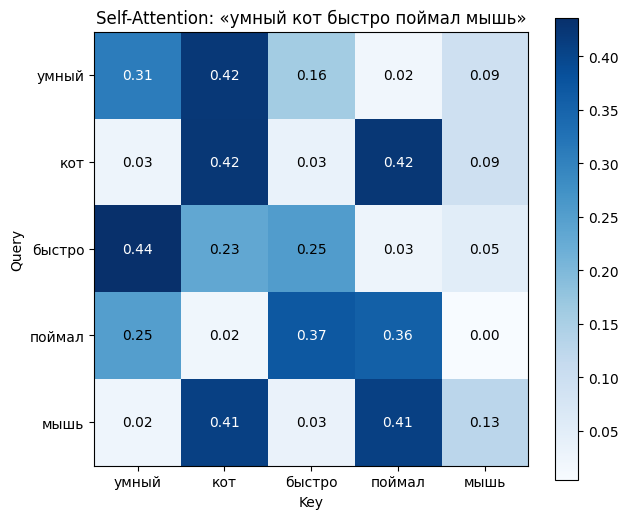

умный   -> больше всего: кот (0.42), меньше всего: поймал (0.02)
кот     -> больше всего: кот (0.42), меньше всего: умный (0.03)
быстро  -> больше всего: умный (0.44), меньше всего: поймал (0.03)
поймал  -> больше всего: быстро (0.37), меньше всего: мышь (0.00)
мышь    -> больше всего: кот (0.41), меньше всего: умный (0.02)


In [ ]:
# Шаг 6. Визуализация attention matrix
plt.figure(figsize=(7,6))
plt.imshow(weights_a, cmap="Blues")
plt.xticks(range(len(words_a)), words_a)
plt.yticks(range(len(words_a)), words_a)
plt.xlabel("Key")
plt.ylabel("Query")
plt.title("Self-Attention: «умный кот быстро поймал мышь»")
for i in range(len(words_a)):
    for j in range(len(words_a)):
        val = weights_a[i, j]
        plt.text(j, i, f"{val:.2f}", ha="center", va="center",
                 color="white" if val > 0.3 else "black")
plt.colorbar()
plt.show()

for i, w in enumerate(words_a):
    row = weights_a[i]
    print(f"{w:7s} -> больше всего: {words_a[row.argmax()]} ({row.max():.2f}), меньше всего: {words_a[row.argmin()]} ({row.min():.2f})")

**Вывод по варианту A.**

| Слово | Больше всего внимания | Меньше всего |
|---|---|---|
| умный | кот (0.42) | поймал (0.02) |
| кот | кот и поймал (по 0.42) | умный (0.03) |
| быстро | умный (0.44) | поймал (0.03) |
| поймал | быстро (0.37), на себя 0.36 | мышь (0.005) |
| мышь | кот и поймал (по 0.41) | умный (0.02) |

Строки матрицы - это вероятностные распределения (каждая сумма = 1).
Видна осмысленная структура: прилагательное «умный» сильнее всего тянется к существу «кот», которое оно определяет; «кот» и «мышь» (существа) обращают внимание на «кот» и на глагол «поймал»; наречие «быстро» больше всего смотрит на «умный» (у обоих велик признак «свойство»), а «поймал» - на «быстро» и на себя. Слабее всего связаны слова с разными ролями (например, «поймал» почти не смотрит на «мышь», а «кот» и «мышь» не обращают внимания на «умный»).
Эти связи получились потому, что я задал embeddings по смыслу (существо / действие / свойство). В реальном Transformer матрицы W обучаются, и такие связи модель находит сама.
Новое представление каждого слова (`output_a`) - это взвешенная смесь V всех слов, то есть контекстный embedding: например, у «мышь» и «кот» выходы получились очень похожими, так как они смотрят на одни и те же слова.

# 22. Итоговые вопросы - ответьте письменно

1. Зачем Transformer нужны Query, Key и Value?

Каждое слово в предложении и задаёт вопрос, и даёт ответ, поэтому из одного слова делают три вектора. Query - это вопрос слова: что мне нужно найти в предложении. Key - это ярлык слова: по нему другие слова видят, подходит ли оно под их вопрос. Value - это то, что слово реально передаёт, если на него обратили внимание. Сначала Query сравнивают с Key всех слов и узнают, на какие слова надо смотреть сильнее. Потом берут Value этих слов, больше от важных и меньше от неважных, и складывают.

2. Зачем Transformer нужен positional encoding и что будет без него?

Self-attention смотрит на все слова сразу и не знает, какое из них стоит первым, а какое последним. Без информации о позиции модель видит просто набор слов и не отличит «кот увидел мышь» от «мышь увидел кота». Она не поймёт, кто что сделал, и потеряет порядок слов. Positional encoding добавляет к каждому слову число, которое показывает его место в предложении.

3. Что значит, что два объекта близко в embedding space, и при чём тут cosine similarity?

Если два объекта близко, значит, модель считает их похожими. Например, cat, dog и tiger лежат рядом, а car, bus и truck в другой группе. Cosine similarity показывает эту близость числом: если оно около 1, объекты очень похожи, около 0 - не связаны, около -1 - противоположны. В нашем примере cat и tiger дают 0.999, то есть почти одно и то же, а cat и car около -1, то есть совсем разные.

4. Чем autoencoder отличается от обычного классификатора?

Классификатор получает на вход картинку, а на выходе даёт название класса (например, «это цифра 7»). Его цель - угадать правильную метку, поэтому для обучения нужна разметка. Autoencoder получает на вход картинку и на выходе тоже даёт картинку, которая должна быть как можно больше похожа на исходную. Его цель - минимально ошибиться при восстановлении (например, по MSE), и метки ему не нужны. Из-за узкого места в середине (bottleneck) он вынужден запомнить только самое главное о картинке.

5. В чём основная идея contrastive learning?

Идея в том, чтобы похожие объекты стояли в пространстве близко, а разные далеко, и всё это без ручной разметки. Positive pair - это два варианта одного и того же объекта, например фото кота и его обрезка. Их сближают. Negative pair - это два разных объекта, например кот и автомобиль. Их отдаляют. Augmentation - это изменения картинки (обрезка, поворот, смена яркости), с помощью которых из одной картинки получают пару. Важно, чтобы augmentation не меняла смысл: если обрезать так, что кота не видно, или повернуть цифру 6 и получить 9, обучение пойдёт неправильно.